# Neural net experiments

**Goal:** see whether a small neural network (scikit-learn's `MLPClassifier`) finds class signal
that carries over to new subjects.

**Background from `ada_boost.ipynb`:** AdaBoost didn't beat the majority baseline on grouped-by-subject
CV, and it predicted all 1s on held-out subjects. The features seem to identify *who* a row came
from more than *what class* it is.

**Why a neural net:** unlike trees, a neural net needs scaled inputs, so we have to choose how to
scale. That makes this a natural place to test the main idea from the AdaBoost notebook: **scaling
each feature within its own subject** to remove each subject's "signature".

No submission in this notebook yet. It only evaluates.

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=UserWarning)  # sklearn feature-name warnings

RANDOM_STATE = 42

## 1. Load and preprocess (same steps as `ada_boost.ipynb` section 3)

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

target = "output"
groups = train["subject"]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    X = pd.get_dummies(X, columns=["state"], dtype=int)
    return X

X_full = prep(train)
X_test = prep(test).reindex(columns=X_full.columns, fill_value=0)
y = train[target]

const_cols = X_full.columns[X_full.nunique() <= 1]
X_full = X_full.drop(columns=const_cols)
X_test = X_test.drop(columns=const_cols)
print(f"Dropped {len(const_cols)} constant columns -> {X_full.shape[1]} features")

Dropped 108 constant columns -> 564 features


## 2. Evaluation harness

This is the same harness as the AdaBoost notebook, with one addition: **ROC AUC**.

- **Accuracy** (the competition metric) can sit at the baseline even when a model has *some* signal,
  if the signal is never strong enough to flip a prediction to 0.
- **AUC** measures whether the model *ranks* class-0 rows below class-1 rows, whatever the threshold.
  An AUC of 0.5 is random guessing and 1.0 is a perfect ranking. If the grouped AUC is clearly above
  0.5, there's real signal that threshold tuning could turn into accuracy.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model, X=None):
    X = X_full if X is None else X
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                           scoring=["accuracy", "f1_macro", "roc_auc"], **kw)
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
        row[f"{cv_name}_auc"] = s["test_roc_auc"].mean()
    results.append(row)
    return pd.Series(row)

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"))

model        majority baseline
strat_acc             0.844895
strat_f1m             0.457964
strat_auc                  0.5
group_acc             0.852051
group_f1m              0.45784
group_auc                  0.5
dtype: object

## 3. Experiment 1: MLP with ordinary (global) scaling

**Hypothesis:** a neural net with standard scaling (mean 0, std 1 for each feature, computed over all
training rows) will act like AdaBoost. It will do fine on subjects it has seen and fall back to
predicting all 1s on new subjects, because global scaling leaves each subject's signature in place.

The scaler sits inside a pipeline, so in each CV fold it's fitted on the training folds only.

In [4]:
def mlp(hidden=(64,), alpha=1e-3):
    return MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, early_stopping=True,
                         max_iter=500, random_state=RANDOM_STATE)

evaluate("MLP (64), global scaling", make_pipeline(StandardScaler(), mlp()))

model        MLP (64), global scaling
strat_acc                    0.845113
strat_f1m                    0.527959
strat_auc                    0.659518
group_acc                    0.837382
group_f1m                    0.465531
group_auc                     0.54741
dtype: object

**Interpretation:** this hypothesis was mostly right. On subjects it has seen, the MLP has real
ranking signal (shuffled AUC 0.66), but on new subjects that drops to 0.55, barely above random.
Grouped accuracy (0.837) is *below* the baseline (0.852). Unlike AdaBoost it does predict some 0s,
but mostly wrongly.

## 4. Experiment 2: MLP with per-subject scaling

**Hypothesis:** if each subject has its own offset and spread (a "signature"), z-scoring every
feature **within each subject** removes it. The model then sees "how unusual is this row *for this
subject*", which should carry over to new subjects. Grouped accuracy and AUC should go up.

**Is this allowed?** Yes. The scaling uses only the feature values of a subject's own rows, never
their labels. For the test set, E and J can be scaled with their own test rows, which needs no
labels either. In grouped CV, the held-out subjects are scaled the same way, so this mirrors the
test situation.

We only scale the continuous sensor features. `phase` and the `state_*` columns are left as they
are, because they describe conditions, not measurements.

In [5]:
cond_cols = ["phase"] + [c for c in X_full.columns if c.startswith("state_")]
sensor_cols = [c for c in X_full.columns if c not in cond_cols]

def per_subject_scale(X, subj):
    X = X.copy()
    g = X[sensor_cols].groupby(subj.values)
    mean = g.transform("mean")
    std = g.transform("std").replace(0, np.nan)
    # A feature that is constant within one subject becomes 0 for that subject
    X[sensor_cols] = ((X[sensor_cols] - mean) / std).fillna(0)
    return X

X_subj = per_subject_scale(X_full, groups)
X_test_subj = per_subject_scale(X_test, test["subject"])  # ready for a later submission

# A final global scaler keeps the condition columns on a similar scale to the rest
evaluate("MLP (64), per-subject scaling", make_pipeline(StandardScaler(), mlp()), X_subj)

model        MLP (64), per-subject scaling
strat_acc                         0.835079
strat_f1m                         0.488764
strat_auc                          0.60982
group_acc                         0.812648
group_f1m                         0.460281
group_auc                         0.490663
dtype: object

**Interpretation:** this hypothesis was wrong. Per-subject scaling made things **worse**: grouped
AUC fell to 0.49 (random) and grouped accuracy to 0.813. So either the class signal isn't a
within-subject change, or scaling within a subject also removed the useful part. One possible
reason: some subjects are almost all one class (K is 100% class 1). For them, "unusual for this
subject" can't mean "class 0".

## 5. Experiment 3: network size and regularisation

**Hypothesis:** with only 11 training subjects, a bigger network will memorise subject-specific
patterns. Stronger L2 regularisation (`alpha`) and smaller layers should carry over better to new
subjects.

This uses whichever scaling did better on grouped AUC in experiments 1 and 2.

In [6]:
res = pd.DataFrame(results).set_index("model")
use_subj = res.loc["MLP (64), per-subject scaling", "group_auc"] > res.loc["MLP (64), global scaling", "group_auc"]
X_best = X_subj if use_subj else X_full
scaling = "per-subject" if use_subj else "global"
print("Using", scaling, "scaling")

grid = []
for hidden in [(16,), (64,), (128, 64)]:
    for alpha in [1e-4, 1e-2, 1.0]:
        s = evaluate(f"MLP {hidden}, alpha={alpha}, {scaling}",
                     make_pipeline(StandardScaler(), mlp(hidden, alpha)), X_best)
        grid.append({"hidden": str(hidden), "alpha": alpha,
                     "group_acc": s.group_acc, "group_auc": s.group_auc})

grid = pd.DataFrame(grid)
grid.pivot(index="hidden", columns="alpha", values="group_auc").round(3)

Using global scaling


alpha,0.0001,0.0100,1.0000
hidden,,,
"(128, 64)",0.590,0.544,0.568
"(16,)",0.517,0.516,0.526
"(64,)",0.551,0.550,0.560


**Interpretation:** all settings are close, with grouped AUC between 0.52 and 0.59. The largest
network with the weakest regularisation, (128, 64) with alpha=0.0001, scores best at 0.59. That's
the opposite of the hypothesis, but the gap is small for a single random seed, so it may be noise.
No setting beats the baseline on grouped accuracy.

## 6. Results so far

In [7]:
pd.DataFrame(results).set_index("model").round(4)

,strat_acc,strat_f1m,strat_auc,group_acc,group_f1m,group_auc
model,,,,,,
majority baseline,0.8449,0.4580,0.5000,0.8521,0.4578,0.5000
"MLP (64), global scaling",0.8451,0.5280,0.6595,0.8374,0.4655,0.5474
"MLP (64), per-subject scaling",0.8351,0.4888,0.6098,0.8126,0.4603,0.4907
"MLP (16,), alpha=0.0001, global",0.8442,0.5391,0.6679,0.8355,0.4665,0.5165
"MLP (16,), alpha=0.01, global",0.8423,0.5415,0.6710,0.8321,0.4614,0.5161
"MLP (16,), alpha=1.0, global",0.8445,0.5403,0.6774,0.8376,0.4608,0.5259
"MLP (64,), alpha=0.0001, global",0.8445,0.5291,0.6606,0.8370,0.4625,0.5506
"MLP (64,), alpha=0.01, global",0.8442,0.5290,0.6606,0.8376,0.4656,0.5505
"MLP (64,), alpha=1.0, global",0.8453,0.5433,0.6833,0.8385,0.4664,0.5605


## 7. Experiment 4: errors and threshold on held-out subjects

**Hypothesis:** even if the model has some ranking signal (grouped AUC > 0.5), the default 0.5
threshold on predicted probability may still predict almost all 1s. Lowering the bar for predicting
0 might raise accuracy.

We get one out-of-fold probability per training row with grouped CV. Each row is then scored by a
model that never saw its subject. We plot accuracy against the threshold.

Best: hidden=(128, 64), alpha=0.0001, scaling=global


Accuracy at 0.5: 0.8174   best: 0.8449 at threshold 0.05


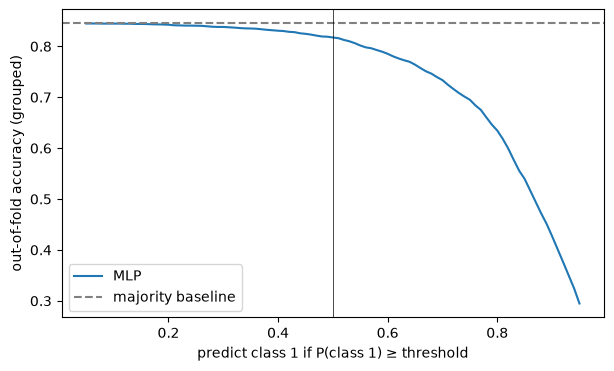

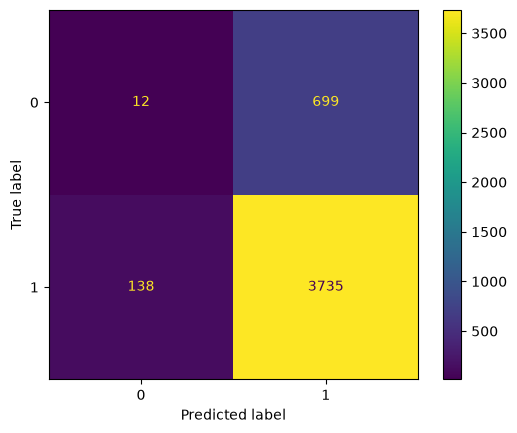

In [8]:
best_row = grid.loc[grid.group_auc.idxmax()]
best_model = make_pipeline(StandardScaler(),
                           mlp(eval(best_row.hidden), best_row.alpha))
print(f"Best: hidden={best_row.hidden}, alpha={best_row.alpha}, scaling={scaling}")

proba_1 = cross_val_predict(best_model, X_best, y, cv=gkf, groups=groups,
                            method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
accs = [accuracy_score(y, (proba_1 >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(accs))]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, accs, label="MLP")
ax.axhline((y == 1).mean(), color="grey", ls="--", label="majority baseline")
ax.axvline(0.5, color="black", lw=0.5)
ax.set_xlabel("predict class 1 if P(class 1) ≥ threshold")
ax.set_ylabel("out-of-fold accuracy (grouped)")
ax.legend()
print(f"Accuracy at 0.5: {accuracy_score(y, (proba_1 >= 0.5).astype(int)):.4f}   "
      f"best: {max(accs):.4f} at threshold {best_t:.2f}")

ConfusionMatrixDisplay(confusion_matrix(y, (proba_1 >= 0.5).astype(int))).plot()

**Interpretation:** at threshold 0.5 the out-of-fold accuracy is 0.817. The best threshold is 0.05,
which predicts class 1 for almost every row and gets 0.845, the baseline. So moving the threshold
can't turn the weak AUC (about 0.59) into an accuracy gain: the model's class-0 guesses are wrong
more often than right at every threshold.

## 8. Feature importance (permutation, held-out subjects)

**Hypothesis:** if per-subject scaling helped, the important features should now be ones that change
*within* a subject between class 0 and class 1, rather than ones that tell subjects apart.

Held-out subjects: ['C', 'I']


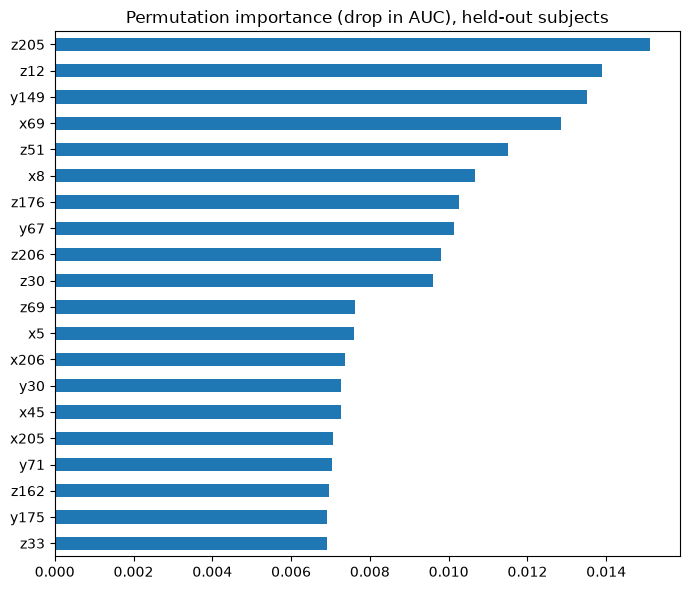

In [9]:
tr_idx, va_idx = next(GroupKFold(n_splits=4).split(X_best, y, groups))
best_model.fit(X_best.iloc[tr_idx], y.iloc[tr_idx])
print("Held-out subjects:", sorted(groups.iloc[va_idx].unique()))

perm = permutation_importance(best_model, X_best.iloc[va_idx], y.iloc[va_idx],
                              scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_best.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6),
                                  title="Permutation importance (drop in AUC), held-out subjects")
plt.tight_layout()

**Interpretation:** the top features are `z205`, `z12`, `y149`, `x69` and `z51`. Each drops AUC by
only about 0.01–0.015 when shuffled, and about 30 features pass 0.005. So the signal is weak and
spread across all three blocks, with no single dominant feature. There's no overlap with AdaBoost's
top features (`phase`, `x50`, `z207`...), which supports the idea that neither model has found a
stable signal.

We use AUC instead of accuracy for importance. A model that predicts all 1s has an accuracy that
never changes when a feature is shuffled, which is why every feature showed about 0 importance in
the AdaBoost notebook.

## 9. Experiment 5: dropout, stronger L2, and subject-aware early stopping (PyTorch)

**Are we using GroupKFold?** Yes. Every `group_*` score above comes from `GroupKFold(n_splits=5)` by
subject. One step didn't respect subjects, though: `MLPClassifier(early_stopping=True)` holds out a
*random* 10% of training rows to decide when to stop. Those rows come from subjects the net is already
training on, so it stops at the point that best fits *known* subjects, which encourages memorising them.

This section rebuilds the MLP in PyTorch so we can change three things:
- **Dropout** after every hidden layer. `MLPClassifier` has no dropout.
- **Decoupled weight decay** (AdamW) instead of the L2 penalty `alpha`. With Adam, an L2 penalty is
  weaker on weights that get large gradients. AdamW shrinks every weight at the same rate, which
  regularises more cleanly. We go up to 1.0.
- **Early stopping on held-out subjects**: inside each GroupKFold training fold, about 20% of the
  training *subjects* form the early-stopping set.

**Hypothesis:** the (128, 64) net from section 5 has the best grouped AUC (0.59) but also the
largest gap from shuffled CV, so it is memorising subjects. Dropout and stronger weight decay should
reduce that and raise grouped AUC. Subject-aware early stopping should stop training before the net
starts fitting subject-specific patterns.

Each setting is averaged over **3 seeds**, because single-seed differences in section 5 were within
noise. Same folds, same global scaling (fitted in each fold), same features as section 5.

In [10]:
import torch
from torch import nn
from joblib import Parallel, delayed
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

def make_net(n_in, hidden, dropout):
    layers, d = [], n_in
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)

def fit_predict(X_tr, y_tr, g_tr, X_va, hidden, dropout, weight_decay, seed,
                es="subject", lr=1e-3, batch=128, max_epochs=200, patience=20, return_epoch=False):
    """Train one net and return P(class 1) for X_va.

    es="subject": early stopping holds out ~20% of the training *subjects*, so training stops
    when the net stops improving on people it hasn't seen. es="row" holds out random rows
    instead, like MLPClassifier(early_stopping=True).
    """
    torch.set_num_threads(1)  # many small nets run in parallel, one core each
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(X_tr)
    X_tr, X_va = scaler.transform(X_tr), scaler.transform(X_va)
    splitter = GroupShuffleSplit if es == "subject" else ShuffleSplit
    fit_idx, es_idx = next(splitter(n_splits=1, test_size=0.2, random_state=seed)
                           .split(X_tr, y_tr, g_tr if es == "subject" else None))
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    Xf, yf, Xe, ye = t(X_tr[fit_idx]), t(y_tr[fit_idx]), t(X_tr[es_idx]), t(y_tr[es_idx])

    net = make_net(X_tr.shape[1], hidden, dropout)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    gen = torch.Generator().manual_seed(seed)
    best_loss, best_state, bad, best_epoch = np.inf, None, 0, 0
    for epoch in range(max_epochs):
        net.train()
        for idx in torch.randperm(len(Xf), generator=gen).split(batch):
            opt.zero_grad()
            loss_fn(net(Xf[idx]).squeeze(1), yf[idx]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            es_loss = loss_fn(net(Xe).squeeze(1), ye).item()
        if es_loss < best_loss - 1e-4:
            best_loss, bad, best_epoch = es_loss, 0, epoch + 1
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    with torch.no_grad():
        proba = torch.sigmoid(net(t(X_va)).squeeze(1)).numpy()
    return (proba, best_epoch) if return_epoch else proba

In [11]:
Xv = X_full.values.astype(np.float32)
yv = y.values.astype(np.float32)
gv = groups.values
folds = list(gkf.split(Xv, yv, gv))
SEEDS = [0, 1, 2]

def grouped_oof(configs):
    """Out-of-fold P(class 1) for every config and seed, using the same GroupKFold folds as above."""
    tasks = [(ci, s, k) for ci in range(len(configs)) for s in SEEDS for k in range(len(folds))]
    preds = Parallel(n_jobs=-1)(
        delayed(fit_predict)(Xv[folds[k][0]], yv[folds[k][0]], gv[folds[k][0]], Xv[folds[k][1]],
                             seed=s, **configs[ci])
        for ci, s, k in tasks)
    oof = np.zeros((len(configs), len(SEEDS), len(yv)))
    for (ci, s, k), p in zip(tasks, preds):
        oof[ci, s, folds[k][1]] = p
    return oof

def fold_scores(p):
    """Mean over folds, like cross_validate, so numbers are comparable with the table above."""
    acc, f1, auc = [], [], []
    for _, va in folds:
        pred = (p[va] >= 0.5).astype(int)
        acc.append(accuracy_score(y.iloc[va], pred))
        f1.append(f1_score(y.iloc[va], pred, average="macro"))
        auc.append(roc_auc_score(y.iloc[va], p[va]))
    return np.mean(acc), np.mean(f1), np.mean(auc)

configs = [dict(hidden=(128, 64), dropout=d, weight_decay=w)
           for d in [0.0, 0.2, 0.4, 0.6] for w in [1e-4, 1e-2, 1e-1, 1.0]]
oof = grouped_oof(configs)

rows = []
for c, o in zip(configs, oof):
    s = np.array([fold_scores(p) for p in o])  # one row per seed
    rows.append({"dropout": c["dropout"], "weight_decay": c["weight_decay"],
                 "group_acc": s[:, 0].mean(), "group_f1m": s[:, 1].mean(),
                 "group_auc": s[:, 2].mean(), "group_auc_seed_std": s[:, 2].std()})
torch_grid = pd.DataFrame(rows)
torch_grid.pivot(index="dropout", columns="weight_decay", values="group_auc").round(3)

weight_decay,0.0001,0.0100,0.1000,1.0000
dropout,,,,
0.0,0.513,0.513,0.512,0.507
0.2,0.508,0.504,0.502,0.505
0.4,0.505,0.505,0.504,0.503
0.6,0.488,0.483,0.486,0.496


,dropout,weight_decay,group_acc,group_f1m,group_auc,group_auc_seed_std
1,0.0,0.0100,0.8520,0.4626,0.5129,0.0088
0,0.0,0.0001,0.8520,0.4626,0.5126,0.0090
2,0.0,0.1000,0.8520,0.4626,0.5124,0.0090
4,0.2,0.0001,0.8521,0.4578,0.5084,0.0131
3,0.0,1.0000,0.8456,0.4561,0.5074,0.0027
7,0.2,1.0000,0.8469,0.4565,0.5053,0.0093


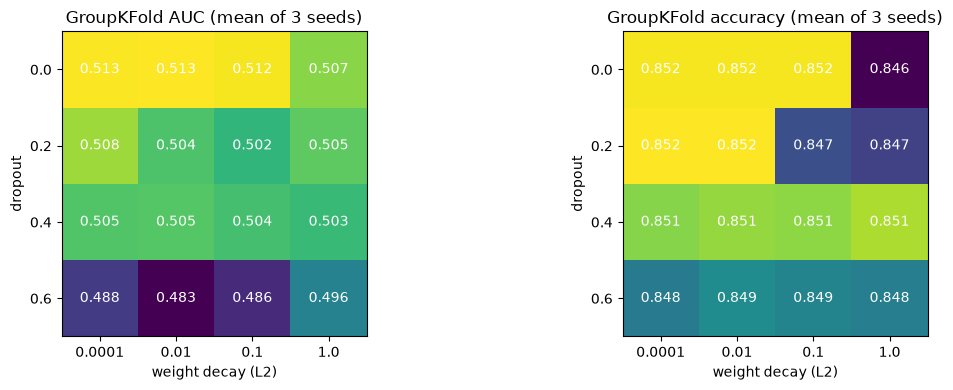

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "group_auc", "GroupKFold AUC"), (axes[1], "group_acc", "GroupKFold accuracy")]:
    piv = torch_grid.pivot(index="dropout", columns="weight_decay", values=col)
    im = ax.imshow(piv.values, cmap="viridis")
    ax.set_xticks(range(piv.shape[1]), piv.columns)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    ax.set_xlabel("weight decay (L2)")
    ax.set_ylabel("dropout")
    ax.set_title(title + " (mean of 3 seeds)")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", color="w")
plt.tight_layout()
torch_grid.sort_values("group_auc", ascending=False).round(4).head(6)

**Interpretation:** this hypothesis was wrong. Every setting scores a grouped AUC of **0.48–0.51**,
which is random and *below* the 0.55–0.59 from `MLPClassifier` in section 5. More dropout makes it
slightly worse (0.6 is the worst row). Weight decay barely matters: each row of the table changes by
≤0.01, which is about the seed std. Grouped accuracy is about 0.852 because the nets predict all 1s.
Section 9b shows why.

### 9b. Which change caused that? Early-stopping split vs dropout/weight decay

Section 9 changed two things at once. Here we cross the early-stopping split (held-out **subjects**
vs random **rows**) with dropout and weight decay, and record the epoch early stopping chose.

In [13]:
abl_cfgs = [dict(es=es, dropout=d, weight_decay=w)
            for es in ["subject", "row"] for d in [0.0, 0.4] for w in [1e-4, 1e-1]]
abl_tasks = [(ci, s, k) for ci in range(len(abl_cfgs)) for s in SEEDS for k in range(len(folds))]
abl_out = Parallel(n_jobs=-1)(
    delayed(fit_predict)(Xv[folds[k][0]], yv[folds[k][0]], gv[folds[k][0]], Xv[folds[k][1]],
                         hidden=(128, 64), seed=s, return_epoch=True, **abl_cfgs[ci])
    for ci, s, k in abl_tasks)
abl = pd.DataFrame([{**abl_cfgs[ci], "group_auc": roc_auc_score(y.iloc[folds[k][1]], p), "best_epoch": e}
                    for (ci, s, k), (p, e) in zip(abl_tasks, abl_out)])
abl.groupby(["es", "dropout", "weight_decay"]).agg(
    group_auc=("group_auc", "mean"), median_epoch=("best_epoch", "median"),
    max_epoch=("best_epoch", "max")).round(3)

group_auc  median_epoch  max_epoch
es      dropout weight_decay                                    
row     0.0     0.0001            0.546           4.0          5
                0.1000            0.550           4.0          5
        0.4     0.0001            0.542           5.0          7
                0.1000            0.546           5.0          7
subject 0.0     0.0001            0.513           2.0          2
                0.1000            0.512           2.0          2
        0.4     0.0001            0.505           2.0          5
                0.1000            0.504           2.0          5

**Interpretation:** the drop comes from the **early-stopping split**, not from dropout or weight
decay:
- With **held-out subjects** for early stopping, the loss on unseen people is lowest after **2 epochs**
  (median). After that, more training only makes predictions on new subjects worse, so the net
  barely trains and its AUC is about 0.51.
- With **random rows** (as `MLPClassifier` does), training runs a little longer (epoch 4–5) and
  grouped AUC is about 0.55, matching section 5. Those extra epochs pick up the weak signal that
  section 5 measured.
- Dropout and weight decay change AUC by ≤0.008 under either split, which is noise.

This is the clearest evidence so far for what the AdaBoost and random forest notebooks suggested: the
signal that transfers between subjects is tiny, and it's learned in the first few epochs. **The
network isn't overfitting because it's too big**, which is the problem dropout and L2 address. It
overfits because almost everything learnable is specific to a subject.

## 10. Experiment 6: does the best regularised net beat the baseline on accuracy?

**Hypothesis:** if dropout and weight decay raise grouped AUC, threshold tuning may now turn it into
accuracy above the all-1s baseline, which section 7 couldn't do.

In [14]:
best_cfg = torch_grid.group_auc.idxmax()
print("Best:", configs[best_cfg])
p_best = oof[best_cfg].mean(axis=0)  # average the 3 seeds
accs = [accuracy_score(y, (p_best >= t).astype(int)) for t in thresholds]
print(f"Pooled OOF accuracy at 0.5: {accuracy_score(y, (p_best >= 0.5).astype(int)):.4f}   "
      f"best: {max(accs):.4f} at threshold {thresholds[int(np.argmax(accs))]:.2f}   "
      f"(all 1s: {(y == 1).mean():.4f})")
print(f"Pooled OOF AUC (seed-averaged): {roc_auc_score(y, p_best):.3f}")

Best: {'hidden': (128, 64), 'dropout': 0.0, 'weight_decay': 0.01}
Pooled OOF accuracy at 0.5: 0.8449   best: 0.8449 at threshold 0.05   (all 1s: 0.8449)
Pooled OOF AUC (seed-averaged): 0.396


**Interpretation:** no gain. Even the best regularised net only matches the all-1s baseline
(0.8449) by predicting all 1s. The pooled out-of-fold AUC (0.40) is *below* 0.5. That happens
because the folds' probabilities are on different scales: the net gives *higher* P(class 1) to
held-out subjects that have more class-0 rows. So any between-subject pattern it learned points the
wrong way on new people.

## 11. Experiment 7: neural net in the hybrid setup (known subjects only)

`random_forest.ipynb` section 12 found the only setup so far that beats the baseline. It splits the
test set:
- **Rows from subjects A–M** (46% of test, also in training): a model on per-subject normalised
  features plus the subject as a one-hot feature, scored with **stratified** CV, because the test
  rows for these subjects look like a random sample of the same recordings.
- **Rows from E and J**: predict 1.

That forest reached **0.867** test-weighted accuracy on known subjects (all 1s: 0.843). Here we
put the PyTorch net in the same setup.

**Hypothesis:** within a known subject the net doesn't need to generalise to new people, so it should
learn the within-subject signal the forest found (stratified macro-F1 0.72). It could beat the forest,
because the normalised features are continuous and correlated, which suits a net better than
axis-aligned tree splits. Dropout and weight decay may matter here, unlike section 9, because the
limit is now ordinary overfitting rather than subject shift.

Setup matches the forest: the per-subject z-score uses each subject's train and test rows (no
labels), there are 5 stratified folds, the threshold is tuned on out-of-fold probabilities, and
accuracy is re-weighted to the test mix of known subjects. Early stopping uses random rows
(`es="row"`), which is right here because we score subjects the model has seen. Each net's
probabilities are averaged over 3 seeds.

In [15]:
both = pd.concat([X_full, X_test], ignore_index=True)
subj_all = pd.concat([train.subject, test.subject], ignore_index=True)
g = both[sensor_cols].groupby(subj_all.values)
both[sensor_cols] = ((both[sensor_cols] - g.transform("mean"))
                     / g.transform("std").replace(0, np.nan)).fillna(0)
subj_onehot = pd.get_dummies(subj_all, prefix="subj", dtype=int).reindex(
    columns=[f"subj_{s}" for s in sorted(train.subject.unique())], fill_value=0)
both = pd.concat([both, subj_onehot], axis=1)
Xh = both.iloc[:len(train)].values.astype(np.float32)
Xh_test = both.iloc[len(train):].values.astype(np.float32)

known = test.subject.isin(train.subject.unique()).values
test_mix = test.subject[known].value_counts(normalize=True)
print(f"{Xh.shape[1]} features; known-subject test rows: {known.mean():.1%}")

def test_weighted_acc(pred):
    per_subj = pd.Series(pred == y.values).groupby(groups.values).mean()
    return (per_subj.reindex(test_mix.index) * test_mix).sum()

575 features; known-subject test rows: 45.7%


In [16]:
sfolds = list(skf.split(Xh, yv))
hyb_cfgs = [dict(hidden=h, dropout=d, weight_decay=w)
            for h in [(64,), (128, 64)] for d in [0.0, 0.3] for w in [1e-2, 1e-1]]
hyb_tasks = [(ci, s, k) for ci in range(len(hyb_cfgs)) for s in SEEDS for k in range(len(sfolds))]
hyb_out = Parallel(n_jobs=-1)(
    delayed(fit_predict)(Xh[sfolds[k][0]], yv[sfolds[k][0]], gv[sfolds[k][0]], Xh[sfolds[k][1]],
                         seed=s, es="row", **hyb_cfgs[ci])
    for ci, s, k in hyb_tasks)
hyb_oof = np.zeros((len(hyb_cfgs), len(SEEDS), len(yv)))
for (ci, s, k), p in zip(hyb_tasks, hyb_out):
    hyb_oof[ci, s, sfolds[k][1]] = p

rows = [{"model": "all 1s", "threshold": np.nan, "strat_acc": (y == 1).mean(), "f1_macro": 0.458,
         "auc": 0.5, "test_weighted_acc": test_weighted_acc(np.ones(len(y), dtype=int))},
        {"model": "random forest (random_forest.ipynb §12)", "threshold": 0.58, "strat_acc": 0.8695,
         "f1_macro": 0.7212, "auc": np.nan, "test_weighted_acc": 0.8666}]
for cfg, o in zip(hyb_cfgs, hyb_oof):
    p = o.mean(axis=0)
    accs = [accuracy_score(y, (p >= t).astype(int)) for t in thresholds]
    t = thresholds[int(np.argmax(accs))]
    pred = (p >= t).astype(int)
    rows.append({"model": f"MLP {cfg['hidden']}, dropout={cfg['dropout']}, wd={cfg['weight_decay']}",
                 "threshold": t, "strat_acc": accuracy_score(y, pred),
                 "f1_macro": f1_score(y, pred, average="macro"), "auc": roc_auc_score(y, p),
                 "test_weighted_acc": test_weighted_acc(pred)})
hyb_results = pd.DataFrame(rows).set_index("model")
hyb_results.sort_values("test_weighted_acc", ascending=False).round(4)

,threshold,strat_acc,f1_macro,auc,test_weighted_acc
model,,,,,
random forest (random_forest.ipynb §12),0.58,0.8695,0.7212,NaN,0.8666
"MLP (64,), dropout=0.3, wd=0.1",0.46,0.8506,0.5682,0.7839,0.8480
"MLP (128, 64), dropout=0.3, wd=0.1",0.52,0.8499,0.5224,0.7810,0.8475
"MLP (64,), dropout=0.3, wd=0.01",0.45,0.8499,0.5613,0.7859,0.8474
"MLP (64,), dropout=0.0, wd=0.01",0.40,0.8493,0.5284,0.7791,0.8468
"MLP (128, 64), dropout=0.3, wd=0.01",0.51,0.8490,0.5129,0.7810,0.8466
"MLP (64,), dropout=0.0, wd=0.1",0.37,0.8490,0.5152,0.7787,0.8466
"MLP (128, 64), dropout=0.0, wd=0.01",0.50,0.8486,0.5160,0.7859,0.8461
"MLP (128, 64), dropout=0.0, wd=0.1",0.50,0.8479,0.5167,0.7859,0.8455


Best MLP: {'hidden': (64,), 'dropout': 0.3, 'weight_decay': 0.1} threshold 0.46


,A,B,C,D,F,G,H,I,K,L,M
mlp_acc,0.966,0.858,0.748,0.936,0.788,0.558,0.856,0.955,1.000,0.912,0.716
all_1s_acc,0.971,0.860,0.756,0.938,0.779,0.492,0.862,0.962,1.000,0.912,0.709
test_share,0.075,0.099,0.090,0.105,0.076,0.111,0.042,0.157,0.087,0.090,0.070


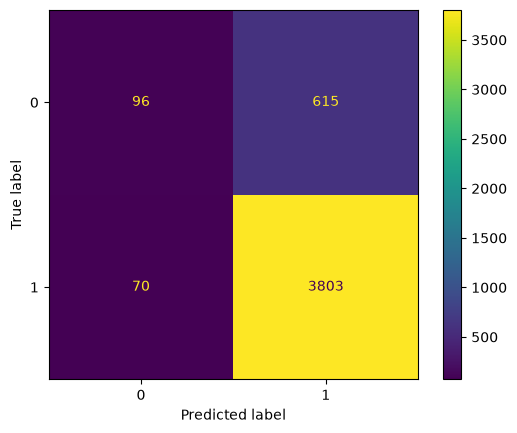

In [17]:
best_hyb = int(np.argmax([test_weighted_acc((o.mean(axis=0) >= hyb_results.iloc[i + 2].threshold).astype(int))
                          for i, o in enumerate(hyb_oof)]))
cfg, t_hyb = hyb_cfgs[best_hyb], hyb_results.iloc[best_hyb + 2].threshold
print("Best MLP:", cfg, f"threshold {t_hyb:.2f}")
pred = (hyb_oof[best_hyb].mean(axis=0) >= t_hyb).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot()
pd.DataFrame({"mlp_acc": pd.Series(pred == y.values).groupby(groups.values).mean(),
              "all_1s_acc": (y == 1).groupby(groups.values).mean(),
              "test_share": test_mix}).round(3).T

**Interpretation:** this was partly right. In the hybrid setup the net finds real signal:
stratified AUC is **0.78–0.79**, compared with 0.51 on unseen subjects (section 9). It also beats
all 1s on every setting. But it turns much less of that ranking into accuracy than the forest does:
the best setting, (64,) with dropout 0.3 and weight decay 0.1, reaches **0.848** test-weighted
(+0.5 pts over all 1s) vs the forest's **0.867** (+2.4 pts). Macro-F1 is 0.57 vs 0.72.
- Almost all of the net's gain comes from **G** (0.49 → 0.56). The forest reached 0.64 there and also
  gained on M, L and B, where the net is flat.
- Dropout 0.3 is in the top 3 settings and weight decay 0.1 is best, so regularisation helps a little
  here, unlike section 9. But the whole spread is 0.0025, about the same size as seed noise.
- Hypothesis (b), that the net would beat the forest, was wrong. On 564 mixed, partly redundant
  features with only about 4.6k rows, the forest is the stronger model.

## 12. Neural-net hybrid submission

Train the best setting on all training rows (3 seeds, averaged), predict the known-subject test rows
with the tuned threshold, and set E and J to 1.

In [18]:
p_test = np.mean([fit_predict(Xh, yv, gv, Xh_test[known], seed=s, es="row", **cfg) for s in SEEDS], axis=0)
nn_hybrid = pd.read_csv("sample_solution.csv")
nn_hybrid["output"] = 1
nn_hybrid.loc[known, "output"] = (p_test >= t_hyb).astype(int)
nn_hybrid.to_csv("submission_nn_hybrid.csv", index=False)

rf_hybrid = pd.read_csv("submission_hybrid.csv")
print(f"Predicted class 0: {(nn_hybrid.output[known] == 0).mean():.1%} of known-subject rows "
      f"(forest hybrid: {(rf_hybrid.output[known] == 0).mean():.1%})")
print(f"Agreement with the forest hybrid on known-subject rows: "
      f"{(nn_hybrid.output[known] == rf_hybrid.output[known]).mean():.1%}")
(nn_hybrid.output[known] == 0).groupby(test.subject[known].values).mean().round(3).rename("pred_frac_0")

Predicted class 0: 3.0% of known-subject rows (forest hybrid: 11.3%)
Agreement with the forest hybrid on known-subject rows: 91.0%


A    0.000
B    0.000
C    0.014
D    0.000
F    0.017
G    0.250
H    0.000
I    0.000
K    0.000
L    0.000
M    0.000
Name: pred_frac_0, dtype: float64

**Interpretation:** the net predicts class 0 for only **3%** of known-subject rows (the forest:
11%), almost all of them in G. It agrees with the forest hybrid on 91% of those rows. Most of the
disagreement is rows the forest calls 0 and the net calls 1. So it is a more cautious version of
the same model, not a different view. **Submit `submission_hybrid.csv` (forest), not this file.**
Its expected gain is about 0.2 pts overall, vs about 1.1 for the forest.

## Summary and next steps

**Result:** no neural net setting beats the majority baseline on grouped accuracy. The best grouped
AUC is 0.59, which is weak signal, and threshold tuning can't turn it into accuracy.

**What we learned:**
- Per-subject scaling **hurt** (grouped AUC 0.49). The "remove each subject's signature" idea from
  the AdaBoost notebook doesn't work in its simple form.
- The MLP has more ranking signal than AdaBoost on seen subjects (shuffled AUC about 0.69), but most
  of it doesn't carry over to new subjects.

- **Dropout and stronger L2 (AdamW weight decay up to 1.0) don't help** (sections 9–10). Grouped AUC
  stays at 0.48–0.51 over 16 settings × 3 seeds. With subject-aware early stopping, the best epoch on
  unseen subjects is about **epoch 2**, so the network's problem isn't too much capacity. Almost
  everything it can learn is specific to a subject.

- **Hybrid setup (sections 11–12):** on known subjects, with per-subject normalisation and subject
  one-hot features, the net has real signal (stratified AUC 0.78). But it beats all 1s by only
  +0.5 pts test-weighted (0.848 vs 0.843), vs +2.4 for the random forest (0.867). The forest hybrid
  remains the best submission.

**Next steps:**
1. Try **gradient boosting** (e.g. `HistGradientBoostingClassifier`) in the hybrid setup. It's the
   model family most likely to beat the forest on this kind of tabular data.
2. Blend the forest and net probabilities on known subjects. They agree on 91% of rows, so the gain
   is likely small, but it's cheap to test.
3. For unseen subjects E and J (54% of test), regularising the network doesn't help (sections 9–9b).
   It needs features that mean the same thing across subjects.